# ELECTRONIC SUPPLEMENTARY MATERIAL 3
# Projecting new samples onto the unsupervised clustering with SOM+K-Means

**Article:** *Beyond bivariate plots: A machine learning workflow for multivariate classification of igneous suites in the northeastern Borborema Province, Brazil*
**Journal:** Earth Science Informatics
**Authors:** Botello, G. E.\*, Hollanda, M. H. B. M., Carneiro, C. C., Marques, G. R., and Lucas, D.

\* Corresponding author
Affiliation: Instituto de Geociências, Universidade de São Paulo, SP, Brazil
E-mail: botello@usp.br

This notebook is a standalone, lightweight companion to the full analysis pipeline (ESM_2). It doesn't repeat any of that pipeline's steps for fitting models. It only loads the SOM that has already been trained and projects new whole-rock geochemical analyses onto it. This allows a reader to classify their own samples without needing to understand or re-run the entire workflow.

1. Libraries and folder configuration
2. Load the trained model (from ESM_2)
3. Pre-process the new samples
4. Project the new samples onto the trained SOM
5. Visualize the projection

---

### A note on why this notebook reuses saved objects instead of recomputing them

Two objects produced by ESM_2 are reused here **exactly as fitted**, never
recomputed from the new data: the trained SOM itself, and the two
`StandardScaler` objects used to standardize trace elements and geochemical
indices. Re-fitting either of these on the new samples alone would silently
place the new samples in the wrong location on the map — the SOM's grid and
the scalers' mean/standard deviation define a coordinate system learned from
the original 771-sample dataset, and a new batch (often just a handful of
samples) has its own, unrelated mean and spread.

## 1. Libraries and folder configuration

In [4]:
# Basic libraries
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, to_rgba
from matplotlib.cm import ScalarMappable
from matplotlib.patches import RegularPolygon, Polygon
from matplotlib.lines import Line2D
import joblib

# SOM
import intrasom
from intrasom import SOMFactory

warnings.filterwarnings("ignore")

from importlib.metadata import version
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("intrasom:", version("intrasom"))

pandas: 3.0.5
numpy: 2.4.6
intrasom: 1.1.2


In [5]:
# FOLDER CONFIGURATION
# This notebook is self-contained: it does not read anything from the ESM_2 folder. "Model/" holds the small set of files exported by ESM_2 that are
# needed to reload the trained SOM and reproduce its exact variable scaling
#   - Granites-DRN-Geochemistry-results-preprocessing.xlsx  (data)
#   - granitoids_final_neurons.parquet                      (trained SOM weights)
#   - params_granitoids_final.json                          (trained SOM parameters)
#   - trace_scaler.joblib, index_scaler.joblib               (fitted scalers)
#   - neurons_5_clusters.npy                                 (K-means cluster assignment per neuron)

ROOT_DIR = Path(".")

PATHS = {
    "new_data":    ROOT_DIR / "Dataset" / "New_Samples_Template.xlsx",
    "model_dir":   ROOT_DIR / "Model",
    "results_dir": ROOT_DIR / "Results",
    "figures_dir": ROOT_DIR / "Figures",
}

for key, p in PATHS.items():
    if key.endswith("_dir"):
        p.mkdir(parents=True, exist_ok=True)

# Same variable set the SOM was trained on (ESM_2, Section 4). Fixed here rather than re-derived, since this notebook does not re-run the filtering
# step that originally produced them.

OXIDES = ["SiO2", "TiO2", "Al2O3", "Fe2O3", "MnO", "MgO", "CaO", "Na2O", "K2O", "P2O5"]
TRACE_ELEMENTS = ["Rb", "Ba", "Sr", "Nb", "Zr", "Y"]
GEOCHEM_INDICES = ["NKC", "A/NK", "A/CNK", "M/MF", "FMT", "K/NK"]

CLR_OXIDES = [f"{c}-CLR" for c in OXIDES]
SCALED_TRACES = [f"{c}_sc" for c in TRACE_ELEMENTS]
SCALED_INDICES = [f"{c}_sc" for c in GEOCHEM_INDICES]
VARIABLES_ML = CLR_OXIDES + SCALED_TRACES + SCALED_INDICES

# Detection-limit replacement rule (same as ESM_2, Section 2.2)
DL_VALUES_BY_TYPE = {"oxide": 0.005, "trace": 0.05}

## 2. Load the trained model (from ESM_2)

Reloads the SOM exactly as it was trained — its neuron weights, training
parameters, and the training dataset (needed by `SOMFactory.load_som` to
reconstruct the model object) — with no retraining involved.

In [7]:
training_data = pd.read_excel(
    PATHS["model_dir"] / "Granites-DRN-Geochemistry-results-preprocessing.xlsx"
)
bmus = pd.read_parquet(PATHS["model_dir"] / "granitoids_final_neurons.parquet")
params = json.load(open(PATHS["model_dir"] / "params_granitoids_final.json", encoding="utf-8"))
clusters_model = np.load(PATHS["model_dir"] / "neurons_5_clusters.npy")

trace_scaler = joblib.load(PATHS["model_dir"] / "trace_scaler.joblib")
index_scaler = joblib.load(PATHS["model_dir"] / "index_scaler.joblib")

values_labels = training_data.set_index(training_data["Label"])[VARIABLES_ML]

som_model = intrasom.SOMFactory.load_som(
    data=values_labels, trained_neurons=bmus, params=params,
)
print("Trained SOM reloaded. Grid size:", params.get("mapsize"))

Loading data...
Loading dataframe...
Normalizing data...
Creating neighborhood...
Creating missing data database
Creating codebook...
Loading distances matrix...
Initializing map...


Creating Neuron Distance Rows:   0%|          | 0/20 [00:00<?, ?rows/s]

Trained SOM reloaded. Grid size: [20, 20]


## 3. Pre-process the new samples

New samples go through the same cleaning and transformation logic as ESM_2, with two differences specific to projecting new data:

- **Major oxides must be complete** for every new sample (the standard set of 10 major oxides from an XRF analysis). Unlike the training pipeline,
  this notebook does not retrain an imputation SOM for a handful of new samples, so rows with any missing oxide cannot be CLR-transformed and are
  dropped from the projection, with a warning.
- **Trace elements and indices may have missing values.** They are standardized with the *saved* `trace_scaler` / `index_scaler` (`.transform`,
  never `.fit_transform` — see the note at the top of this notebook).

In [9]:
def replace_below_detection_limit(df, oxides, trace_elements, dl_values_by_type):
    """Replace '<value' (below detection limit) strings with a fixed value
    per variable type, then coerce numeric-looking strings to float."""
    def _replace(x, col):
        if isinstance(x, str) and x.strip().startswith("<"):
            if col in oxides:
                return dl_values_by_type["oxide"]
            elif col in trace_elements:
                return dl_values_by_type["trace"]
            return np.nan
        return x

    df_clean = df.apply(lambda col: col.map(lambda x: _replace(x, col.name)))
    df_clean = df_clean.map(
        lambda x: float(x) if isinstance(x, str) and x.replace(".", "", 1).isdigit() else x
    )
    return df_clean


def compute_geochemical_indices(df):
    """Same formulas as ESM_2, Section 2.3."""
    df = df.copy()
    df["NKC"] = df["Na2O"] + df["K2O"] - df["CaO"]
    df["A/NK"] = (df["Al2O3"] / 101.96) / ((df["Na2O"] / 61.98) + (df["K2O"] / 94.20))
    df["A/CNK"] = (df["Al2O3"] / 101.96) / (
        (df["CaO"] / 56.08) + (df["Na2O"] / 61.98) + (df["K2O"] / 94.20)
    )
    df["FeOT"] = df["Fe2O3"] * 0.89981
    df["M/MF"] = (df["MgO"] / 40.3 * 1000) / ((df["FeOT"] / 71.8 * 1000) + (df["MgO"] / 40.3 * 1000))
    df["FMT"] = (
        (df["FeOT"] / 71.8 * 1000) + (df["MgO"] / 40.3 * 1000) + (df["TiO2"] / 79.8 * 1000)
    )
    df["K/NK"] = (df["K2O"] / 94.20 * 2 * 1000) / (
        (df["Na2O"] / 61.98 * 2 * 1000) + (df["K2O"] / 94.20 * 2 * 1000)
    )
    return df


def clr_transform(df, columns, suffix="-CLR"):
    """Centered log-ratio transform (row-wise; same as ESM_2, Section 2.4).
    Rows with any non-positive or missing value cannot be transformed and
    are returned as NaN for that row.
    """
    values = df[columns].values.astype(float)
    complete = ~np.isnan(values).any(axis=1) & (values > 0).all(axis=1)

    clr_values = np.full(values.shape, np.nan)
    geometric_means = np.exp(np.mean(np.log(values[complete]), axis=1))
    clr_values[complete] = np.log(values[complete] / geometric_means[:, np.newaxis])

    return pd.DataFrame(clr_values, columns=[f"{c}{suffix}" for c in columns], index=df.index), complete

In [10]:
# --- Run: load and pre-process the new samples ------------------------------
df_new = pd.read_excel(PATHS["new_data"])
print("New samples loaded:", df_new.shape)

df_new_clean = replace_below_detection_limit(df_new, OXIDES, TRACE_ELEMENTS, DL_VALUES_BY_TYPE)
df_new_refined = compute_geochemical_indices(df_new_clean)

clr_oxides_new, complete_oxides = clr_transform(df_new_refined, OXIDES)
n_dropped = (~complete_oxides).sum()
if n_dropped:
    print(f"WARNING: {n_dropped} sample(s) dropped - incomplete major-oxide data:")
    print(df_new_refined.loc[~complete_oxides, "Sample"].tolist())

df_new_refined = df_new_refined.loc[complete_oxides].reset_index(drop=True)
clr_oxides_new = clr_oxides_new.loc[complete_oxides].reset_index(drop=True)

# Standardize with the SAVED scalers - .transform only, never .fit_transform
# (see the note at the top of this notebook).
scaled_traces_new = pd.DataFrame(
    trace_scaler.transform(df_new_refined[TRACE_ELEMENTS]),
    columns=SCALED_TRACES, index=df_new_refined.index,
)
scaled_indices_new = pd.DataFrame(
    index_scaler.transform(df_new_refined[GEOCHEM_INDICES]),
    columns=SCALED_INDICES, index=df_new_refined.index,
)

df_new_final = pd.concat([df_new_refined, clr_oxides_new, scaled_traces_new, scaled_indices_new], axis=1)
df_new_final.to_excel(
    PATHS["results_dir"] / "New_samples_transformation.xlsx", index=False
)
print("\nPre-processed new samples ready for projection:", df_new_final.shape)
df_new_final.head()

New samples loaded: (1, 17)

Pre-processed new samples ready for projection: (1, 46)


,Sample,SiO2,TiO2,Al2O3,Fe2O3,MnO,MgO,CaO,Na2O,K2O,...,Sr_sc,Nb_sc,Zr_sc,Y_sc,NKC_sc,A/NK_sc,A/CNK_sc,M/MF_sc,FMT_sc,K/NK_sc
0,Example-01,68.5,0.45,15.2,3.1,0.06,1.2,2.8,3.6,3.9,...,-0.412333,-0.59439,-0.467463,-0.152346,-0.348057,0.468093,0.36508,0.989431,-0.198048,-0.37805


## 4. Project the new samples onto the trained SOM

`project_nan_data` locates the best-matching unit for each new sample on
the already-trained grid — the SOM itself is not modified. It natively
handles any remaining missing values in the trace-element/index columns.

In [12]:
# --- Run: project new samples ------------------------------------------------
values_labels_new = df_new_final.set_index(df_new_final["Sample"])[VARIABLES_ML]

proj_data_result = som_model.project_nan_data(data_proj=values_labels_new)

proj_data_result.to_excel(PATHS["results_dir"] / "Projected_samples_BMU.xlsx")
print("Projection complete.")
proj_data_result

Projection complete.


,BMU,Udist,Ret_x,Ret_y,Cub_x,Cub_y,Cub_z,B_SiO2-CLR,B_TiO2-CLR,B_Al2O3-CLR,...,B_Sr_sc,B_Nb_sc,B_Zr_sc,B_Y_sc,B_NKC_sc,B_A/NK_sc,B_A/CNK_sc,B_M/MF_sc,B_FMT_sc,B_K/NK_sc
Example-01,76,0.249987,15,3,14,-17,3,3.506831,-1.25511,2.05466,...,0.006773,-0.238182,-0.485186,-0.773832,-0.171356,0.303093,0.226448,0.735106,0.002613,-0.424988


## 5. Visualize the projection

In [14]:
class SOMPlotting:
    """
    This subclass makes the plots for the SOM, including the unified distance matrix (U-matrix), number of hits, neurons template, component plots and clusters outlines.
    
    Methods:
        umatrix(neurons_matrix): plot the unified distance matrix (U-matrix) by calculating the mean distance of each neuron to their immediate neighbors in the latent space and plotting it as a heatmap. The method needs the neurons matrix.
        
        hits(): plot the hits of each neuron.

        template(): plots the neurons template.

        locate_neurons(neurons_indices): plot the neurons if given their indices.

        component(values): choose a component to plot given the values of each neuron.

        kmeans(neurons_clusters): plot the clusters outline, given the labels of each neuron.
    
    Usage:
        >>> fig, axs = plt.subplots(2, 2, figsize=(10, 5))
        >>> plot = Plotting(som)
        >>> sm1 = plot.u_matrix(axs[0,0], neurons_matrix)
        >>> plot.hits(axs[0,0], bmus)
        >>> fig.colorbar(sm1, ax=axs[0,0], location='right')
        >>> plot.template(axs[0,1])
        >>> sm2 = plot.component(axs[1,0], values=values[:,component])
        >>> fig.colorbar(sm2, ax=axs[1,0], location='right')
        >>> clusters_legend = plot.kmeans(axs[1,1], neurons_clusters)
        >>> axs[1,1].legend(handles=clusters_legend, loc='upper left', bbox_to_anchor=(1, 1))
    """

    def __init__(self, mapshape, lattice, cell_size):
        self.mapshape = mapshape
        self.lattice = lattice
        self.cell_size = cell_size
        x_spacing, y_spacing, toroid_squared_distances, grid_coords = self.map_params()
        self.x_spacing = x_spacing
        self.y_spacing = y_spacing
        self.toroid_distances = toroid_squared_distances
        self.grid_coords = grid_coords

    def map_params(self):
        """
        Returns the euclidean distance matrix in the toroid latent space G
        for each node in the rectangular or hexagonal grid.
        """

        n_rows, n_cols = self.mapshape

        # Step 1: Calculate coordinates of each cell
        rows, cols = np.meshgrid(
            np.arange(n_rows, dtype=float),
            np.arange(n_cols, dtype=float),
            indexing="ij"
        )

        grid_coords = np.zeros((n_rows, n_cols, 2), dtype=float)

        if self.lattice == "square":
            x_spacing = self.cell_size
            y_spacing = self.cell_size

            grid_coords[..., 1] = cols * x_spacing
            grid_coords[..., 0] = rows * y_spacing

        elif self.lattice == "hexagonal":
            hex_radius = self.cell_size / 2
            x_spacing = np.sqrt(3.0) * hex_radius
            y_spacing = (3 / 2) * hex_radius

            grid_coords[..., 1] = (
                cols * x_spacing
                + (x_spacing / 2) * (rows % 2)
            )
            grid_coords[..., 0] = rows * y_spacing

        else:
            raise ValueError(f"Unknown lattice type: {self.lattice}")

        # Step 2: Calculate the distance matrix of the grid
        # considering a toroidal projection.
        torus_width = n_cols * x_spacing
        torus_height = n_rows * y_spacing

        dx = grid_coords[..., 1].ravel()
        dx_first_distances = np.abs(dx[:, None] - dx)
        dx_second_distances = np.abs(torus_width - dx_first_distances)
        dx_minimum_distances = np.minimum(
            dx_first_distances,
            dx_second_distances
        )

        dy = grid_coords[..., 0].ravel()
        dy_first_distances = np.abs(dy[:, None] - dy)
        dy_second_distances = np.abs(torus_height - dy_first_distances)
        dy_minimum_distances = np.minimum(
            dy_first_distances,
            dy_second_distances
        )

        toroid_squared_distances = (
            dx_minimum_distances**2
            + dy_minimum_distances**2
        )

        return (
            x_spacing,
            y_spacing,
            toroid_squared_distances,
            grid_coords
        )
    def umatrix(self, ax, neurons_matrix):
        """
        Plot the unified distance matrix (U-matrix).
        """

        n_rows, n_cols = self.mapshape
        x_spacing = self.x_spacing
        y_spacing = self.y_spacing
        toroid_distances = self.toroid_distances
        grid_coords = self.grid_coords

        torus_width = n_cols * x_spacing
        torus_height = n_rows * y_spacing

        neurons_matrix = np.asarray(neurons_matrix)

        # Pairwise distances between neurons in data space.
        neurons_distances = np.linalg.norm(
            neurons_matrix[:, None, :] - neurons_matrix[None, :, :],
            axis=-1
        )

        if self.lattice == "square":
            # ---------------------------------------------------------
            # Step 1: Create the toroidal neuron-index templates.
            # ---------------------------------------------------------
            t = np.arange(n_rows * n_cols, dtype=int).reshape(
                n_rows, n_cols
            )

            t_rows = np.concatenate(
                [t[-1][None, :], t, t[0][None, :]],
                axis=0
            )
            t_cols = np.concatenate(
                [t[:, -1][:, None], t, t[:, 0][:, None]],
                axis=1
            )

            u_rows = np.stack(
                [t_rows[i:i + 2, :] for i in range(n_rows + 1)],
                axis=0
            ).transpose(0, 2, 1)

            u_cols = np.stack(
                [t_cols[:, i:i + 2] for i in range(n_cols + 1)],
                axis=0
            ).transpose(1, 0, 2)

            # ---------------------------------------------------------
            # Step 2: Replace each diagonal value with the mean
            # distance to the four closest SOM neighbors.
            # ---------------------------------------------------------
            neighs_indices = np.argsort(
                toroid_distances,
                axis=1
            )[:, 1:5]

            row_indices = np.arange(
                neighs_indices.shape[0]
            )[:, None]

            distances_neighs = neurons_distances[
                row_indices,
                neighs_indices
            ]

            neighs_mean_distances = np.mean(
                distances_neighs,
                axis=1
            )

            umat_distances = neurons_distances.copy()
            np.fill_diagonal(
                umat_distances,
                neighs_mean_distances
            )

            # ---------------------------------------------------------
            # Step 3: Gather distances for the U-matrix edges.
            # ---------------------------------------------------------
            umat_rows = umat_distances[
                u_rows[..., 0],
                u_rows[..., 1]
            ]

            umat_cols = umat_distances[
                u_cols[..., 0],
                u_cols[..., 1]
            ]

            # ---------------------------------------------------------
            # Step 4: Create U-matrix grid coordinates.
            # ---------------------------------------------------------
            even_rows, even_cols = np.meshgrid(
                np.arange(n_rows + 1, dtype=float),
                np.arange(n_cols, dtype=float),
                indexing="ij"
            )

            umat_rows_coords = np.zeros(
                (n_rows + 1, n_cols, 2),
                dtype=float
            )
            umat_rows_coords[..., 1] = even_cols * x_spacing
            umat_rows_coords[..., 0] = (
                -y_spacing / 2
                + even_rows * y_spacing
            )

            odd_rows, odd_cols = np.meshgrid(
                np.arange(n_rows, dtype=float),
                np.arange(n_cols + 1, dtype=float),
                indexing="ij"
            )

            umat_cols_coords = np.zeros(
                (n_rows, n_cols + 1, 2),
                dtype=float
            )
            umat_cols_coords[..., 1] = (
                -x_spacing / 2
                + odd_cols * x_spacing
            )
            umat_cols_coords[..., 0] = (
                odd_rows * y_spacing
            )

            # ---------------------------------------------------------
            # Step 5: Plotting.
            # ---------------------------------------------------------
            norm = Normalize(
                vmin=np.min(distances_neighs),
                vmax=np.max(distances_neighs)
            )
            cmap = plt.get_cmap("jet")
            sm = ScalarMappable(norm=norm, cmap=cmap)

            for center, value in zip(
                umat_rows_coords.reshape(-1, 2),
                umat_rows.ravel()
            ):
                u_even = RegularPolygon(
                    (center[1], -center[0]),
                    numVertices=4,
                    radius=self.cell_size / 2,
                    edgecolor="none",
                    facecolor=cmap(norm(value))
                )
                ax.add_patch(u_even)

            for center, value in zip(
                umat_cols_coords.reshape(-1, 2),
                umat_cols.ravel()
            ):
                u_odd = RegularPolygon(
                    (center[1], -center[0]),
                    numVertices=4,
                    radius=self.cell_size / 2,
                    edgecolor="none",
                    facecolor=cmap(norm(value))
                )
                ax.add_patch(u_odd)

            for i, center in enumerate(grid_coords.reshape(-1, 2)):
                u_square = RegularPolygon(
                    (center[1], -center[0]),
                    numVertices=4,
                    radius=(np.sqrt(2) / 4) * self.cell_size,
                    orientation=np.pi / 4,
                    edgecolor="none",
                    facecolor=cmap(norm(umat_distances[i, i]))
                )
                ax.add_patch(u_square)

            ax.set_xlim(-x_spacing, torus_width)
            ax.set_ylim(-torus_height, y_spacing)

        elif self.lattice == "hexagonal":
            hex_radius = self.cell_size / 2

            # ---------------------------------------------------------
            # Step 1: Create the expanded U-matrix index template.
            # ---------------------------------------------------------
            u = np.zeros(
                (n_rows * 2 + 1, n_cols * 2 + 1, 2),
                dtype=int
            )

            t = np.arange(
                n_rows * n_cols,
                dtype=int
            ).reshape(n_rows, n_cols)

            t = np.concatenate(
                [t[-1, :][None, :], t, t[0, :][None, :]],
                axis=0
            )
            t = np.concatenate(
                [t[:, -1][:, None], t, t[:, 0][:, None]],
                axis=1
            )

            for i in range(n_rows):
                for j in range(n_cols):
                    if i % 2 == 0:
                        u[i * 2, j * 2] = [t[i + 1, j + 1], t[i, j]]
                        u[i * 2, j * 2 + 1] = [
                            t[i + 1, j + 1], t[i, j + 1]
                        ]
                        u[i * 2 + 1, j * 2] = [
                            t[i + 1, j + 1], t[i + 1, j]
                        ]
                        u[i * 2 + 1, j * 2 + 1] = [
                            t[i + 1, j + 1], t[i + 1, j + 1]
                        ]
                        u[i * 2 + 1, j * 2 + 2] = [
                            t[i + 1, j + 1], t[i + 1, j + 2]
                        ]
                        u[i * 2 + 2, j * 2] = [
                            t[i + 1, j + 1], t[i + 2, j]
                        ]
                        u[i * 2 + 2, j * 2 + 1] = [
                            t[i + 1, j + 1], t[i + 2, j + 1]
                        ]
                    else:
                        u[i * 2, j * 2 + 1] = [
                            t[i + 1, j + 1], t[i, j + 1]
                        ]
                        u[i * 2, j * 2 + 2] = [
                            t[i + 1, j + 1], t[i, j + 2]
                        ]
                        u[i * 2 + 1, j * 2] = [
                            t[i + 1, j + 1], t[i + 1, j]
                        ]
                        u[i * 2 + 1, j * 2 + 1] = [
                            t[i + 1, j + 1], t[i + 1, j + 1]
                        ]
                        u[i * 2 + 1, j * 2 + 2] = [
                            t[i + 1, j + 1], t[i + 1, j + 2]
                        ]
                        u[i * 2 + 2, j * 2 + 1] = [
                            t[i + 1, j + 1], t[i + 2, j + 1]
                        ]
                        u[i * 2 + 2, j * 2 + 2] = [
                            t[i + 1, j + 1], t[i + 2, j + 2]
                        ]

            # Top-right and bottom-left positions correspond to the
            # distance between the first and last neuron.
            u[0, -1] = [t[0, 0], t[-1, -1]]
            u[-1, 0] = [t[0, 0], t[-1, -1]]

            # ---------------------------------------------------------
            # Step 2: Replace each diagonal value with the mean
            # distance to the six closest SOM neighbors.
            # ---------------------------------------------------------
            neighs_indices = np.argsort(
                toroid_distances,
                axis=1
            )[:, 1:7]

            row_indices = np.arange(
                neighs_indices.shape[0]
            )[:, None]

            distances_neighs = neurons_distances[
                row_indices,
                neighs_indices
            ]

            neighs_mean_distances = np.mean(
                distances_neighs,
                axis=1
            )

            umat_distances = neurons_distances.copy()
            np.fill_diagonal(
                umat_distances,
                neighs_mean_distances
            )

            # ---------------------------------------------------------
            # Step 3: Gather distances for the U-matrix.
            # ---------------------------------------------------------
            umat = umat_distances[
                u[..., 0],
                u[..., 1]
            ]

            # ---------------------------------------------------------
            # Step 4: Create U-matrix grid coordinates.
            # ---------------------------------------------------------
            umat_coords = np.zeros(
                (n_rows * 2 + 1, n_cols * 2 + 1, 2),
                dtype=float
            )

            for i in range(n_rows * 2 + 1):
                for j in range(n_cols * 2 + 1):
                    if i % 2 == 0:
                        umat_coords[i, j] = [
                            (-y_spacing / 2)
                            + y_spacing * (i / 2),
                            (-x_spacing / 4)
                            + (x_spacing / 2) * j
                        ]
                    elif i % 4 == 1:
                        umat_coords[i, j] = [
                            (-y_spacing / 2)
                            + y_spacing * (i / 2),
                            (-x_spacing / 2)
                            + (x_spacing / 2) * j
                        ]
                    elif i % 4 == 3:
                        umat_coords[i, j] = [
                            (-y_spacing / 2)
                            + y_spacing * (i / 2),
                            (x_spacing / 2) * j
                        ]

            # ---------------------------------------------------------
            # Step 5: Plotting.
            # ---------------------------------------------------------
            norm = Normalize(
                vmin=np.min(umat),
                vmax=np.max(umat)
            )
            cmap = plt.get_cmap("jet")
            sm = ScalarMappable(norm=norm, cmap=cmap)

            for center, value in zip(
                umat_coords.reshape(-1, 2),
                umat.ravel()
            ):
                u_hex = RegularPolygon(
                    (center[1], -center[0]),
                    numVertices=6,
                    radius=hex_radius / 2,
                    edgecolor="none",
                    facecolor=cmap(norm(value))
                )
                ax.add_patch(u_hex)

            ax.set_xlim(
                -(3 / 4) * x_spacing,
                torus_width + (x_spacing / 4)
            )
            ax.set_ylim(
                (-torus_height) + (1 / 4) * hex_radius,
                (5 / 4) * hex_radius
            )

        else:
            raise ValueError(f"Unknown lattice type: {self.lattice}")

        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])

        return sm
    def hits(self, ax, bmus):
        """
        Plot the hits of each neuron in the map.

        bmus: the BMU of each sample. Indices must start at 0.

        """

        # Load parameters
        n_rows, n_cols = self.mapshape
        x_spacing = self.x_spacing
        y_spacing = self.y_spacing
        grid_coords = self.grid_coords
        torus_width = n_cols*x_spacing
        torus_height = n_rows*y_spacing

        if self.lattice == "square":
            hit_counts = np.bincount(bmus, minlength=n_rows*n_cols)
            max_count = np.max(hit_counts)
            for i, square_center in enumerate(grid_coords.reshape(-1, 2)):
                hit_square = RegularPolygon(
                    (square_center[1],-square_center[0]),
                    numVertices=4,
                    radius=(np.sqrt(2)/2)*self.cell_size*(hit_counts[i]/max_count),
                    orientation=(np.pi/4),
                    edgecolor='none',
                    facecolor='white'
                )
                ax.add_patch(hit_square)

            ax.set_xlim(-x_spacing, torus_width)
            ax.set_ylim(-torus_height, y_spacing)

        elif self.lattice == "hexagonal":
            hex_radius = self.cell_size/2
            hit_counts = np.bincount(bmus, minlength=n_rows*n_cols)
            max_count = np.max(hit_counts)
            for i, hex_center in enumerate(grid_coords.reshape(-1, 2)):
                hit_hex = RegularPolygon(
                    (hex_center[1],-hex_center[0]),
                    numVertices=6,
                    radius=hex_radius*(hit_counts[i]/max_count),
                    edgecolor='none',
                    facecolor='white'
                )
                ax.add_patch(hit_hex)

            ax.set_xlim(-(3/4)*x_spacing, torus_width+(x_spacing/4))
            ax.set_ylim((-torus_height)+(1/4)*hex_radius, (5/4)*hex_radius)

        ax.set_aspect('equal')
        ax.set_xticks([])
        ax.set_yticks([])

    def template(self, ax):
        """
        Plot neurons template in the given ax.
        """
        # Load parameters
        n_rows, n_cols = self.mapshape
        x_spacing = self.x_spacing
        y_spacing = self.y_spacing
        grid_coords = self.grid_coords
        torus_width = n_cols*x_spacing
        torus_height = n_rows*y_spacing
        
        if self.lattice == "square":
            # Plot square centers
            for i, square_center in enumerate(grid_coords.reshape(-1, 2)):
                neuron_square = RegularPolygon(
                    (square_center[1],-square_center[0]),
                    numVertices=4,
                    radius=(np.sqrt(2)/2)*self.cell_size,
                    orientation=(np.pi/4),
                    edgecolor='k',
                    facecolor='none'
                )
                ax.add_patch(neuron_square)
                ax.text(square_center[1], -square_center[0], str(i), ha='center', va='center')

            ax.set_xlim(-x_spacing, torus_width)
            ax.set_ylim(-torus_height, y_spacing)
        
        elif self.lattice == "hexagonal":
            hex_radius = self.cell_size/2
            for i, hex_center in enumerate(grid_coords.reshape(-1, 2)):
                neuron_hex = RegularPolygon(
                    (hex_center[1],-hex_center[0]),
                    numVertices=6,
                    radius=hex_radius,
                    edgecolor='k',
                    facecolor='none'
                )
                ax.add_patch(neuron_hex)
                ax.text(hex_center[1], -hex_center[0], str(i), ha='center', va='center')

            ax.set_xlim(-(3/4)*x_spacing, torus_width+(x_spacing/4))
            ax.set_ylim((-torus_height)+(1/4)*hex_radius, (5/4)*hex_radius)

        ax.set_aspect('equal')
        ax.set_xticks([])
        ax.set_yticks([])

    def locate_neurons(self, ax, neurons_indices):
        """
        Locate neurons template in the given ax.

        neurons_indices: indices of the neurons that must be located (starting at 0).
        """
        # Load parameters
        n_rows, n_cols = self.mapshape
        x_spacing = self.x_spacing
        y_spacing = self.y_spacing
        grid_coords = self.grid_coords
        torus_width = n_cols*x_spacing
        torus_height = n_rows*y_spacing
        
        if self.lattice == "square":
            # Plot square centers
            for i, square_center in enumerate(grid_coords.reshape(-1, 2)):
                if i in neurons_indices:
                    neuron_square = RegularPolygon(
                        (square_center[1],-square_center[0]),
                        numVertices=4,
                        radius=(np.sqrt(2)/2)*self.cell_size,
                        orientation=(np.pi/4),
                        edgecolor='k',
                        facecolor='gray',
                        alpha=0.7
                    )
                    ax.add_patch(neuron_square)

            ax.set_xlim(-x_spacing, torus_width)
            ax.set_ylim(-torus_height, y_spacing)
        
        elif self.lattice == "hexagonal":
            hex_radius = self.cell_size/2
            for i, hex_center in enumerate(grid_coords.reshape(-1, 2)):
                if i in neurons_indices:
                    neuron_hex = RegularPolygon(
                        (hex_center[1],-hex_center[0]),
                        numVertices=6,
                        radius=hex_radius,
                        edgecolor='k',
                        facecolor='gray',
                        alpha=0.7
                    )
                    ax.add_patch(neuron_hex)

            ax.set_xlim(-(3/4)*x_spacing, torus_width+(x_spacing/4))
            ax.set_ylim((-torus_height)+(1/4)*hex_radius, (5/4)*hex_radius)

        ax.set_aspect('equal')
        ax.set_xticks([])
        ax.set_yticks([])

    def component(self, ax, values):
        """
        Plot the neurons with the denormalized weights of a given component.

        values: the numpy array containing the values of each neuron.
        """
        # Load parameters
        n_rows, n_cols = self.mapshape
        x_spacing = self.x_spacing
        y_spacing = self.y_spacing
        grid_coords = self.grid_coords
        torus_width = n_cols*x_spacing
        torus_height = n_rows*y_spacing

        # Component plots
        norm = Normalize(vmin=np.min(values), vmax=np.max(values))
        cmap = plt.get_cmap('jet')
        sm = ScalarMappable(norm=norm, cmap=cmap)
        
        if self.lattice == "square": 
            # Plot squares
            for i, square_center in enumerate(grid_coords.reshape(-1, 2)):
                neuron_square = RegularPolygon(
                    (square_center[1], -square_center[0]),
                    numVertices=4,
                    radius=(np.sqrt(2)/4)*self.cell_size,
                    orientation=(np.pi/4),
                    edgecolor='none',
                    facecolor=cmap(norm(values[i]))
                )
                ax.add_patch(neuron_square)
            
            ax.set_aspect('equal')
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlim(-x_spacing, torus_width)
            ax.set_ylim(-torus_height, y_spacing)

        if self.lattice == "hexagonal":
            hex_radius = self.cell_size/2
            
            # Plot hexagons
            for i, hex_center in enumerate(grid_coords.reshape(-1, 2)):
                neuron_hex = RegularPolygon(
                    (hex_center[1], -hex_center[0]),
                    numVertices=6,
                    radius=hex_radius,
                    edgecolor='none',
                    facecolor=cmap(norm(values[i]))
                )
                ax.add_patch(neuron_hex)
            
            ax.set_aspect('equal')
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlim(-(3/4)*x_spacing, torus_width+(x_spacing/4))
            ax.set_ylim((-torus_height)+(1/4)*hex_radius, (5/4)*hex_radius)

        return sm

    def kmeans(self, ax, neurons_clusters, alpha=1.0, edgecolor='k'):
        """
        Plot the K-means clusters of neurons.

        neurons_clusters: the numpy array containing the indices of each neuron's cluster (starting at 0).
        alpha: transparency of each neuron's fill color (1.0 = opaque, 0.0 =
            fully transparent). Use a value below 1 to let a background
            layer (e.g. the U-matrix) remain visible through the cluster
            colors.
        edgecolor: outline color of each neuron; set to 'none' to hide it.
        """
        # Load SOM latent space parameters
        n_rows, n_cols = self.mapshape
        x_spacing = self.x_spacing
        y_spacing = self.y_spacing
        grid_coords = self.grid_coords
        torus_width = n_cols*x_spacing
        torus_height = n_rows*y_spacing

        # Load output parameters from the clustering of neurons by KMeans
        n_clusters = len(np.unique(neurons_clusters))

        # Get a color for each cluster, with the requested transparency
        base_colors = plt.cm.gist_rainbow(np.linspace(0, 1, n_clusters))
        colors = [to_rgba(c, alpha=alpha) for c in base_colors]

        if self.lattice == "square":
            for i, square_center in enumerate(grid_coords.reshape(-1, 2)):
                cluster_square = RegularPolygon(
                    (square_center[1],-square_center[0]),
                    numVertices=4,
                    radius=(np.sqrt(2)/2)*self.cell_size,
                    orientation=(np.pi/4),
                    edgecolor=edgecolor,
                    facecolor=colors[neurons_clusters[i]]
                )
                ax.add_patch(cluster_square)

            ax.set_xlim(-x_spacing, torus_width)
            ax.set_ylim(-torus_height, y_spacing)

        elif self.lattice == "hexagonal":
            hex_radius = self.cell_size/2
            for i, hex_center in enumerate(grid_coords.reshape(-1, 2)):
                cluster_hex = RegularPolygon(
                    (hex_center[1],-hex_center[0]),
                    numVertices=6,
                    radius=hex_radius,
                    edgecolor=edgecolor,
                    facecolor=colors[neurons_clusters[i]]
                )
                ax.add_patch(cluster_hex)

            ax.set_xlim(-(3/4)*x_spacing, torus_width+(x_spacing/4))
            ax.set_ylim((-torus_height)+(1/4)*hex_radius, (5/4)*hex_radius)

        ax.set_aspect('equal')
        ax.set_xticks([])
        ax.set_yticks([])
        legend_elements = [Line2D([0], [0], marker='o', color='w', markerfacecolor=base_colors[i], markersize=10, label=f'Cluster {str(i+1)}') for i in range(n_clusters)]

        return legend_elements

    def kmeans_merged(self, ax, neurons_clusters, lw=1.0, alpha=0.5):
        """
        Plot K-means clusters of SOM neurons as merged cluster boundaries.

        Parameters
        ----------
        ax : matplotlib.axes.Axes
            Axes on which the SOM clusters will be plotted.

        neurons_clusters : array-like
            Cluster assignment for each neuron, starting at 0.

        lw : float, default=2.5
            Line width of cluster boundaries.

        alpha : float, default=0.5
            Transparency of cluster boundaries.

        Returns
        -------
        legend_elements : list
            Matplotlib Line2D objects for the cluster legend.
        """

        # ---------------------------------------------------------
        # SOM geometry
        # ---------------------------------------------------------
        n_rows, n_cols = self.mapshape
        grid_coords = np.asarray(self.grid_coords).reshape(-1, 2)

        x_spacing = self.x_spacing
        y_spacing = self.y_spacing

        torus_width = n_cols * x_spacing
        torus_height = n_rows * y_spacing

        neurons_clusters = np.asarray(neurons_clusters)
        n_clusters = len(np.unique(neurons_clusters))

        # ---------------------------------------------------------
        # Cluster colors
        # ---------------------------------------------------------
        colors = plt.cm.gist_rainbow(
            np.linspace(0, 1, n_clusters)
        )

        # ---------------------------------------------------------
        # Helper: trace outer edges
        # ---------------------------------------------------------
        def _merge_edges(edges):
            """
            Keep only edges belonging to the exterior of a cluster
            and connect them into contours.
            """

            # Edges appearing twice are internal edges
            outer_edges = [
                list(edge)
                for edge, count in edges.items()
                if count == 1
            ]

            contours = []

            while outer_edges:

                contour = [
                    outer_edges[0][0],
                    outer_edges[0][1]
                ]
                outer_edges.pop(0)

                changed = True

                while changed:
                    changed = False

                    for i, (p1, p2) in enumerate(outer_edges):

                        if np.allclose(contour[-1], p1):
                            contour.append(p2)

                        elif np.allclose(contour[-1], p2):
                            contour.append(p1)

                        else:
                            continue

                        outer_edges.pop(i)
                        changed = True
                        break

                contours.append(contour)

            return contours

        # ---------------------------------------------------------
        # Helper: add an edge to dictionary
        # ---------------------------------------------------------
        def _add_edge(edge_dict, p1, p2):

            p1 = tuple(np.round(p1, 5))
            p2 = tuple(np.round(p2, 5))

            edge = tuple(sorted([p1, p2]))

            edge_dict[edge] = edge_dict.get(edge, 0) + 1

       # ---------------------------------------------------------
        # HEXAGONAL LATTICE
        # ---------------------------------------------------------
        if self.lattice == "hexagonal":
        
            hex_radius = self.cell_size / 2
        
            # One edge dictionary for each cluster
            cluster_edges = [
                {} for _ in range(n_clusters)
            ]
        
            for i, center in enumerate(grid_coords):
        
                # Same coordinate convention as your original kmeans()
                x = center[1]
                y = -center[0]
        
                cluster = neurons_clusters[i]
        
                # -------------------------------------------------
                # Hexagon vertices
                # -------------------------------------------------
                angles = np.arange(6) * np.pi / 3 + np.pi / 6
        
                vertices = np.column_stack([
                    x + hex_radius * np.cos(angles),
                    y + hex_radius * np.sin(angles)
                ])
        
                # -------------------------------------------------
                # Add hexagon edges
                # -------------------------------------------------
                for k in range(6):
        
                    p1 = vertices[k]
                    p2 = vertices[(k + 1) % 6]
        
                    _add_edge(
                        cluster_edges[cluster],
                        p1,
                        p2
                    )
        
            # -----------------------------------------------------
            # Draw merged boundaries
            # -----------------------------------------------------
            for cluster in range(n_clusters):
        
                contours = _merge_edges(
                    cluster_edges[cluster]
                )
        
                for contour in contours:
        
                    ax.add_patch(
                        Polygon(
                            contour,
                            closed=True,
                            fill=False,
                            edgecolor=colors[cluster],
                            linewidth=lw,
                            alpha=alpha,
                            joinstyle="round"
                        )
                    )
        
            ax.set_xlim(
                -(3 / 4) * x_spacing,
                torus_width + (x_spacing / 4)
            )
        
            ax.set_ylim(
                (-torus_height) + (1 / 4) * hex_radius,
                (5 / 4) * hex_radius
            )
        # ---------------------------------------------------------
        # SQUARE LATTICE
        # ---------------------------------------------------------
        elif self.lattice == "square":

            square_radius = (
                np.sqrt(2) / 2
            ) * self.cell_size

            cluster_edges = [
                {} for _ in range(n_clusters)
            ]

            for i, center in enumerate(grid_coords):

                x = center[1]
                y = -center[0]

                cluster = neurons_clusters[i]

                # Square vertices
                half = self.cell_size / np.sqrt(2)

                vertices = np.array([
                    [x - half, y - half],
                    [x + half, y - half],
                    [x + half, y + half],
                    [x - half, y + half]
                ])

                for k in range(4):

                    p1 = vertices[k]
                    p2 = vertices[(k + 1) % 4]

                    _add_edge(
                        cluster_edges[cluster],
                        p1,
                        p2
                    )

            # Draw merged boundaries
            for cluster in range(n_clusters):

                contours = _merge_edges(
                    cluster_edges[cluster]
                )

                for contour in contours:

                    ax.add_patch(
                        Polygon(
                            contour,
                            closed=True,
                            fill=False,
                            edgecolor=colors[cluster],
                            linewidth=lw,
                            alpha=alpha,
                            joinstyle="round"
                        )
                    )

            ax.set_xlim(
                -x_spacing,
                torus_width
            )

            ax.set_ylim(
                -torus_height,
                y_spacing
            )

        else:
            raise ValueError(
                f"Unknown lattice type: {self.lattice}"
            )

        # ---------------------------------------------------------
        # Axes formatting
        # ---------------------------------------------------------
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])

        # ---------------------------------------------------------
        # Legend
        # ---------------------------------------------------------
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                color="w",
                markerfacecolor=colors[i],
                markersize=10,
                label=f"Cluster {i + 1}"
            )
            for i in range(n_clusters)
        ]

        return legend_elements

Auto-detected BMU column: 'BMU'


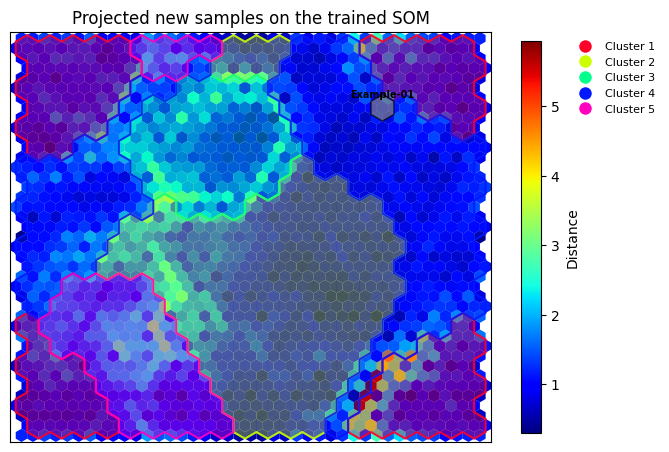

In [24]:
# --- Run: build the ESM_4 visualization -------------------------------------
# Auto-detect the BMU column in proj_data_result (same defensive pattern used in ESM_2 for the template-neuron section, since the exact column name
# cannot be verified without running IntraSOM directly).
candidate_cols = [c for c in proj_data_result.columns if "bmu" in c.lower()]
if len(candidate_cols) == 1:
    bmu_col = candidate_cols[0]
    print(f"Auto-detected BMU column: '{bmu_col}'")
elif len(candidate_cols) > 1:
    raise ValueError(
        f"Multiple possible BMU columns found: {candidate_cols}. "
        "Set `bmu_col` manually to the correct one."
    )
else:
    print("Could not auto-detect a BMU column. Available columns:")
    print(list(proj_data_result.columns))
    raise ValueError("Set `bmu_col` manually, then re-run this cell.")

# IntraSOM's BMU indices are 1-based in results_dataframe (see cell 5's "-1" adjustment for hits()); proj_data_result is expected to follow the
# same convention. Adjust `bmu_is_one_indexed` below if a mismatch is seen.
bmu_is_one_indexed = True
offset = 1 if bmu_is_one_indexed else 0

new_sample_neurons = (proj_data_result[bmu_col].values - offset).astype(int)
new_sample_names = proj_data_result.index.tolist()

# ---------------------------------------------------------------------------
# Figure sized to Earth Science Informatics' maximum figure width (174 mm).
# ---------------------------------------------------------------------------
mm_to_in = 1 / 25.4
fig_width_mm, fig_height_mm = 174, 150

fig, ax = plt.subplots(figsize=(fig_width_mm * mm_to_in, fig_height_mm * mm_to_in))
plot = SOMPlotting(mapshape=(20, 20), lattice="hexagonal", cell_size=1.0)

# Background: trained U-matrix, then semi-transparent cluster fills on top
# (so the U-matrix distances remain visible through the cluster colors),
# then crisp cluster boundary outlines for clarity.
sm = plot.umatrix(ax, som_model.codebook.matrix)
plot.kmeans(ax, clusters_model.reshape(-1) - 1, alpha=0.35, edgecolor='none')
clusters_legend = plot.kmeans_merged(ax, clusters_model.reshape(-1) - 1, lw=1.5, alpha=0.9)

# Foreground: the new samples' actual projected neurons, highlighted and labeled.
plot.locate_neurons(ax, new_sample_neurons.tolist())

grid_coords = np.asarray(plot.grid_coords).reshape(-1, 2)
for neuron_idx, sample_name in zip(new_sample_neurons, new_sample_names):
    x, y = grid_coords[neuron_idx][1], -grid_coords[neuron_idx][0]
    ax.annotate(
        sample_name, (x, y), fontsize=7, fontweight="bold", color="black",
        ha="center", va="center", xytext=(0, 10), textcoords="offset points",
    )

fig.colorbar(sm, ax=ax, location="right", label="Distance", shrink=0.7)
ax.legend(handles=clusters_legend, loc="upper left", bbox_to_anchor=(1.15, 1), fontsize=8, frameon=False)
ax.set_title("Projected new samples on the trained SOM", fontsize=12)

plt.tight_layout()
plt.savefig(PATHS["figures_dir"] / "New_samples_projection.pdf", dpi=300, bbox_inches="tight")
plt.show()